# NB17: End-to-End Tropical Scenario with RELIC Production Functors

This notebook executes a generated humid-tropical scenario using only production RELIC modules:
- `FarquharPhotosynthesis`
- `AutotrophicRespiration`
- `PenmanMonteithET`
- `BucketSoilMoisture`

The forcing is generated inside the notebook. No external data, no external packages beyond the local RELIC environment, and no toy NumPy/Scipy process construction are used in the runtime chain.

Execution scope: these are direct scientific-kernel calls with a notebook-local
state loop, not a RELICSimulator registration/transaction demonstration. The
maintenance and growth respiration inputs are explicitly prescribed fractions
of GPP for this experiment, not separately evaluated respiratory process laws.


## Architecture Anchor

This notebook is aligned with `docs\source\architecture_overview.md` and the relevant theory/API pages under `docs\source`.
All computations below are intended to use actual RELIC functors, the actual simulator or orchestration layer, and real validation pathways rather than notebook-defined pseudo-process equations.


## Learning Goals

- Assemble a multi-process case simulation from actual RELIC production functors.
- Inspect forcing, state, flux, and cumulative-budget diagnostics over a realistic multi-day window.
- Learn which outputs are scientifically meaningful enough for downstream evaluation notebooks.


## 1. Scenario Configuration

Representative humid tropical evergreen canopy with generated forcing and a 1800 s time step.

In [1]:
# ---------------------------------------------------------------
# References:
#   RELIC architecture overview: docs/source/architecture_overview.md
#   Campbell and Norman (1998) for diurnal forcing design logic
# Mathematical expression:
#   No ecological process is solved in this cell.
#   This cell only defines scenario configuration and execution controls.
# Parameter meanings:
#   dt_seconds: simulation time step [s]
#   duration_days: scenario duration [day]
#   lai: canopy leaf area index [m2 m-2]
#   extreme_event_days: deterministic storm-event indices [day]
# ---------------------------------------------------------------

import os
import sys

PROJECT_ROOT = os.environ.get('RELIC_PROJECT_ROOT', os.getcwd())
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

sim_config = {
    'site': {
        'name': 'Representative_Tropical_Evergreen',
        'lat': -3.0,
        'lon': -55.0,
        'elevation_m': 120.0,
        'canopy_height_m': 32.0,
        'lai': 4.6,
    },
    'simulation': {
        'dt_seconds': 1800,
        'duration_days': 60,
        'device': 'cpu',
    },
    'initial_state': {
        'soil_moisture': 0.43,
        'co2_concentration': 412.0,
        'surface_resistance': 140.0,
    },
    'forcing': {
        'extreme_event_days': [5, 21, 37],
        'description': 'Generated humid-tropical forcing with deterministic synoptic and convective variability',
    },
}

print('=== Generated Tropical Scenario Configuration ===')
for section, params in sim_config.items():
    print(f'[{section}]')
    if isinstance(params, dict):
        for key, value in params.items():
            print(f'  {key}: {value}')
    else:
        print(f'  value: {params}')
print('[OK] Scenario configuration ready')

=== Generated Tropical Scenario Configuration ===
[site]
  name: Representative_Tropical_Evergreen
  lat: -3.0
  lon: -55.0
  elevation_m: 120.0
  canopy_height_m: 32.0
  lai: 4.6
[simulation]
  dt_seconds: 1800
  duration_days: 60
  device: cpu
[initial_state]
  soil_moisture: 0.43
  co2_concentration: 412.0
  surface_resistance: 140.0
[forcing]
  extreme_event_days: [5, 21, 37]
  description: Generated humid-tropical forcing with deterministic synoptic and convective variability
[OK] Scenario configuration ready


## 2. Import and Instantiate Real RELIC Functors

We import **production scientific modules** directly from `relic.scientific`:
- `FarquharPhotosynthesis` -- the authoritative C3 photosynthesis model
- `AutotrophicRespiration` -- maintenance + growth respiration composition
- `PenmanMonteithET` -- atmospheric evapotranspiration demand
- `BucketSoilMoisture` -- soil water update; net radiation remains a prescribed driver

In [2]:
# ---------------------------------------------------------------
# References:
#   Farquhar et al. (1980), Planta -- C3 photosynthesis
#   Amthor (2000) -- maintenance and growth respiration
#   Monteith (1965) and Allen et al. (1998) -- Penman-Monteith ET
#   Manabe (1969) -- bucket soil-water balance
# Mathematical expression:
#   Photosynthesis: A = min(Ac, Aj) - Rd
#   Autotrophic respiration: R_auto = R_maintenance + R_growth
#   Evapotranspiration: ET = [s(Rn-G) + rho cp VPD ga] / [lambda (s + gamma (1 + ga/gc))]
#   Bucket water balance: dtheta/dt = (P - ET - Q - D) / (rho_w Z)
# Parameter meanings:
#   vcmax25, jmax25, rd25: Farquhar biochemical parameters
#   biomass_leaf, biomass_stem, biomass_root: live biomass pools for respiration [kg C m-2]
#   surface_resistance: bulk canopy resistance for ET [s m-1]
#   soil_moisture: volumetric water content [m3 m-3]
# Units:
#   vcmax25/rd25 [umol CO2 m-2 s-1], jmax25 [umol e- m-2 s-1]; water/carbon mass rates [kg m-2 s-1].
# Domain/constraints:
#   Explicit state-based canopy resistance; the 1800 s step is inside the PM hourly formulation.
# Sign convention:
#   GPP is positive uptake; respiration and ET are positive outward fluxes.
# ---------------------------------------------------------------

import warnings
warnings.filterwarnings('ignore', message='The pynvml package is deprecated.*')

import torch

from relic.scientific.biosphere.photosynthesis.farquhar import FarquharPhotosynthesis
from relic.scientific.biosphere.respiration.autotrophic_respiration import AutotrophicRespiration
from relic.scientific.hydrosphere.evapotranspiration.penman_monteith import PenmanMonteithET
from relic.scientific.hydrosphere.soil_moisture.bucket import BucketSoilMoisture


def unwrap_scalar(value):
    if hasattr(value, 'value'):
        value = value.value
    if isinstance(value, torch.Tensor):
        return float(value.detach().cpu().item())
    return float(value)


photo = FarquharPhotosynthesis(
    name='nb17_farquhar_photosynthesis',
    vcmax25=34.0,
    jmax25=70.0,
    rd25=0.85,
    device=torch.device('cpu'),
    enable_gpu=False,
)
resp = AutotrophicRespiration(
    name='nb17_autotrophic_respiration',
    device=torch.device('cpu'),
)
et_functor = PenmanMonteithET(name='nb17_penman_monteith_et', config={'canopy_resistance_source': 'state'})
bucket = BucketSoilMoisture(name='nb17_bucket_soil_moisture')

biomass_leaf = torch.tensor(0.75, dtype=torch.float32)
biomass_stem = torch.tensor(5.20, dtype=torch.float32)
biomass_root = torch.tensor(1.80, dtype=torch.float32)

print('=== RELIC Production Functors ===')
for label, functor in [
    ('Photosynthesis', photo),
    ('Autotrophic respiration', resp),
    ('Evapotranspiration', et_functor),
    ('Soil moisture', bucket),
]:
    metadata = functor.metadata
    print(f'{label}: {metadata.name}')
    print(f'  category: {metadata.category}')
    print(f'  outputs:  {metadata.output_variables[:6]}')
print('[OK] Production functors instantiated')

=== RELIC Production Functors ===
Photosynthesis: nb17_farquhar_photosynthesis
  category: ProcessCategory.BIOLOGICAL_PROCESS
  outputs:  ['gross_photosynthesis', 'net_photosynthesis', 'gross_primary_productivity', 'electron_transport_rate', 'diagnostics.photosynthesis.dark_respiration', 'diagnostics.photosynthesis.transport_limited']
Autotrophic respiration: nb17_autotrophic_respiration
  category: ProcessCategory.BIOLOGICAL_PROCESS
  outputs:  ['total_autotrophic_respiration', 'net_primary_productivity', 'diagnostics.autotrophic_respiration.maintenance_component', 'diagnostics.autotrophic_respiration.growth_component', 'diagnostics.autotrophic_respiration.maintenance_fraction', 'diagnostics.autotrophic_respiration.growth_fraction']
Evapotranspiration: nb17_penman_monteith_et
  category: ProcessCategory.TRANSPORT_MECHANISM
  outputs:  ['evapotranspiration_flux', 'latent_heat_flux', 'diagnostics.vapor_pressure_deficit', 'diagnostics.aerodynamic_conductance', 'diagnostics.canopy_conduct

## 3. Run the Scientific-Kernel Scenario Loop

Execute the configured 60 days, with 48 half-hourly calls per day. Each state
matches the current scientific kernel inputs. Calls to `forward()` bypass the
FunctorBase governed call and simulator StateManager transaction; this notebook
does not certify either of those pathways. Returned bucket next states are
assigned exactly once to the local trajectory. Existing numerical range checks
remain below.


In [3]:
# ---------------------------------------------------------------
# References:
#   Generated forcing design follows standard tropical diurnal and synoptic patterns
#   Farquhar et al. (1980), Amthor (2000), Monteith (1965), Manabe (1969)
# Mathematical expression:
#   solar(t) = max(sin(pi * (hour - 6) / 12), 0)
#   GPP_t = FarquharPhotosynthesis(state_t)
#   R_auto,t = AutotrophicRespiration(state_t)
#   ET_t = PenmanMonteithET(state_t)
#   theta_(t+dt) = BucketSoilMoisture(theta_t, P_t, ET_t)
# Parameter meanings:
#   dt: integration step [s]
#   solar: normalized daylight factor [0-1]
#   precip_mm_h: generated rainfall intensity [mm h-1]
#   theta: volumetric soil moisture [m3 m-3]
# ---------------------------------------------------------------

import math

dt = float(sim_config['simulation']['dt_seconds'])
duration_days = int(sim_config['simulation']['duration_days'])
steps_per_day = int(86400 // dt)
n_steps = duration_days * steps_per_day
extreme_event_days = set(sim_config['forcing']['extreme_event_days'])

soil_moisture = torch.tensor(sim_config['initial_state']['soil_moisture'], dtype=torch.float32)
water_stress = torch.tensor(1.0, dtype=torch.float32)

step_history = {
    'step_index': [],
    'day_index': [],
    'hour_of_day': [],
    'air_temp_c': [],
    'relative_humidity': [],
    'par': [],
    'net_radiation': [],
    'precip_flux': [],
    'gpp': [],
    'r_auto': [],
    'net_canopy': [],
    'et_flux': [],
    'soil_moisture': [],
    'water_stress': [],
    'runoff_flux': [],
    'drainage_flux': [],
}

for step in range(n_steps):
    time_seconds = step * dt
    hour_of_day = (time_seconds / 3600.0) % 24.0
    day_index = step // steps_per_day

    solar = max(0.0, math.sin(math.pi * (hour_of_day - 6.0) / 12.0)) if 6.0 <= hour_of_day <= 18.0 else 0.0
    cloud_factor = min(1.0, max(0.32, 0.80 + 0.20 * math.sin(2.0 * math.pi * day_index / 11.0 + 0.4)))
    storm_cycle = max(0.0, math.sin(2.0 * math.pi * day_index / 10.0 - 0.9)) ** 8
    convective_pulse = max(0.0, math.sin(math.pi * (hour_of_day - 16.0) / 3.0)) if 16.0 <= hour_of_day <= 19.0 else 0.0
    frontal_cycle = max(0.0, math.sin(2.0 * math.pi * day_index / 21.0 + 1.1)) ** 12
    nocturnal_pulse = max(0.0, math.sin(math.pi * (hour_of_day - 19.0) / 4.0)) if 19.0 <= hour_of_day <= 23.0 else 0.0
    extreme_flag = 1.0 if day_index in extreme_event_days else 0.0

    precip_mm_h = (
        65.0 * storm_cycle * (convective_pulse ** 6)
        + 10.0 * frontal_cycle * (nocturnal_pulse ** 4)
        + 170.0 * extreme_flag * (convective_pulse ** 4)
    )
    par_value = 1150.0 * solar * cloud_factor * (0.95 - 0.12 * extreme_flag * convective_pulse)
    air_temp_c = 24.0 + 4.2 * solar + 1.1 * math.sin(2.0 * math.pi * day_index / 15.0) - 1.5 * storm_cycle - 0.6 * extreme_flag * convective_pulse
    relative_humidity = min(
        0.985,
        max(
            0.48,
            0.92 - 0.24 * solar + 0.12 * storm_cycle + 0.05 * math.cos(2.0 * math.pi * day_index / 9.0) + 0.06 * extreme_flag * convective_pulse,
        ),
    )
    net_radiation = max(8.0, 28.0 + 380.0 * solar * cloud_factor - 40.0 * storm_cycle - 50.0 * extreme_flag * convective_pulse)

    # ---------------------------------------------------------------
    # References:
    #   Farquhar et al. (1980); Medlyn et al. (2002)
    # Mathematical expression:
    #   A = min(Ac, Aj) - Rd
    # Parameter meanings:
    #   air_temperature [K], atmospheric_co2_ppm [ppm], ppfd [umol m-2 s-1],
    #   leaf_area_index [m2 m-2], water_stress_factor [0-1]
    # ---------------------------------------------------------------
    photo_state = {
        'air_temperature': torch.tensor(air_temp_c + 273.15, dtype=torch.float32),
        'atmospheric_co2_ppm': torch.tensor(sim_config['initial_state']['co2_concentration'], dtype=torch.float32),
        'ppfd': torch.tensor(par_value, dtype=torch.float32),
        'leaf_area_index': torch.tensor(sim_config['site']['lai'], dtype=torch.float32),
        'water_stress_factor': water_stress,
        'temperature_stress_factor': torch.tensor(1.0, dtype=torch.float32),
        'ozone_stress_factor': torch.tensor(1.0, dtype=torch.float32),
        'vcmax_scaling': torch.tensor(1.0, dtype=torch.float32),
        'jmax_scaling': torch.tensor(1.0, dtype=torch.float32),
        'vapor_pressure_deficit': torch.tensor(max(100.0, (1.0 - relative_humidity) * 2500.0), dtype=torch.float32),
    }
    photo_out = photo.forward(photo_state, time=time_seconds, dt=dt)
    gpp = unwrap_scalar(photo_out['gross_primary_productivity'])

    # ---------------------------------------------------------------
    # References:
    #   Amthor (2000); Thornley and Cannell (2000)
    # Mathematical expression:
    #   R_auto = R_maintenance + R_growth
    # Parameter meanings:
    #   gross_primary_productivity, maintenance_respiration_total, growth_respiration_total [kg C m-2 s-1]
    # ---------------------------------------------------------------
    gross_primary_productivity = photo_out['gross_primary_productivity'].value
    resp_state = {
        'gross_primary_productivity': gross_primary_productivity,
        'maintenance_respiration_total': 0.15 * gross_primary_productivity,
        'growth_respiration_total': 0.10 * gross_primary_productivity,
    }
    resp_out = resp.forward(resp_state, time=time_seconds, dt=dt)
    r_auto = unwrap_scalar(resp_out['total_autotrophic_respiration'])

    # ---------------------------------------------------------------
    # References:
    #   Monteith (1965); Allen et al. (1998)
    # Mathematical expression:
    #   ET = [s(Rn-G) + rho cp VPD ga] / [lambda (s + gamma (1 + ga/gc))]
    # Parameter meanings:
    #   net_radiation [W m-2], air_temperature [K], relative_humidity [0-1],
    #   wind_speed [m s-1], surface_resistance [s m-1]
    # ---------------------------------------------------------------
    et_state = {
        'net_radiation': torch.tensor(net_radiation, dtype=torch.float32),
        'air_temperature': torch.tensor(air_temp_c + 273.15, dtype=torch.float32),
        'wind_speed': torch.tensor(1.3 + 0.7 * solar + 0.15 * extreme_flag + 0.25 * storm_cycle, dtype=torch.float32),
        'atmospheric_pressure': torch.tensor(101325.0, dtype=torch.float32),
        'relative_humidity': torch.tensor(relative_humidity, dtype=torch.float32),
        'surface_resistance': torch.tensor(sim_config['initial_state']['surface_resistance'], dtype=torch.float32),
    }
    et_out = et_functor.forward(et_state, time=time_seconds, dt=dt)
    et_flux = unwrap_scalar(et_out['evapotranspiration_flux'])

    # ---------------------------------------------------------------
    # References:
    #   Manabe (1969); Rodriguez-Iturbe and Porporato (2004)
    # Mathematical expression:
    #   theta_(t+dt) = theta_t + (P - ET - Q - D) dt / (rho_w Z)
    # Parameter meanings:
    #   soil_moisture [m3 m-3], precipitation_flux [kg m-2 s-1],
    #   evapotranspiration_flux [kg m-2 s-1]
    # ---------------------------------------------------------------
    bucket_state = {
        'soil_moisture': soil_moisture,
        'precipitation_flux': torch.tensor(precip_mm_h / 3600.0, dtype=torch.float32),
        'evapotranspiration_flux': et_out['evapotranspiration_flux'].value,
    }
    bucket_out = bucket.forward(bucket_state, time=time_seconds, dt=dt)
    soil_moisture = bucket_out['soil_moisture'].value.detach().clone()
    water_stress = bucket_out['diagnostics.soil_moisture_bucket']['water_stress_factor'].detach().clone()
    runoff_flux = unwrap_scalar(bucket_out['surface_runoff_flux'])
    drainage_flux = unwrap_scalar(bucket_out['drainage_flux'])

    step_history['step_index'].append(step)
    step_history['day_index'].append(day_index)
    step_history['hour_of_day'].append(hour_of_day)
    step_history['air_temp_c'].append(air_temp_c)
    step_history['relative_humidity'].append(relative_humidity)
    step_history['par'].append(par_value)
    step_history['net_radiation'].append(net_radiation)
    step_history['precip_flux'].append(precip_mm_h / 3600.0)
    step_history['gpp'].append(gpp)
    step_history['r_auto'].append(r_auto)
    step_history['net_canopy'].append(gpp - r_auto)
    step_history['et_flux'].append(et_flux)
    step_history['soil_moisture'].append(unwrap_scalar(soil_moisture))
    step_history['water_stress'].append(unwrap_scalar(water_stress))
    step_history['runoff_flux'].append(runoff_flux)
    step_history['drainage_flux'].append(drainage_flux)

for key, values in step_history.items():
    step_history[key] = torch.tensor(values, dtype=torch.float32)

daily = {
    'day_number': torch.arange(1, duration_days + 1, dtype=torch.float32),
    'gpp_gC_day': step_history['gpp'].view(duration_days, steps_per_day).sum(dim=1) * dt * 1000.0,
    'r_auto_gC_day': step_history['r_auto'].view(duration_days, steps_per_day).sum(dim=1) * dt * 1000.0,
    'net_canopy_gC_day': step_history['net_canopy'].view(duration_days, steps_per_day).sum(dim=1) * dt * 1000.0,
    'et_mm_day': step_history['et_flux'].view(duration_days, steps_per_day).sum(dim=1) * dt,
    'precip_mm_day': step_history['precip_flux'].view(duration_days, steps_per_day).sum(dim=1) * dt,
    'runoff_mm_day': step_history['runoff_flux'].view(duration_days, steps_per_day).sum(dim=1) * dt,
    'drainage_mm_day': step_history['drainage_flux'].view(duration_days, steps_per_day).sum(dim=1) * dt,
    'mean_soil_moisture': step_history['soil_moisture'].view(duration_days, steps_per_day).mean(dim=1),
    'min_soil_moisture': step_history['soil_moisture'].view(duration_days, steps_per_day).min(dim=1).values,
    'max_soil_moisture': step_history['soil_moisture'].view(duration_days, steps_per_day).max(dim=1).values,
    'mean_air_temp_c': step_history['air_temp_c'].view(duration_days, steps_per_day).mean(dim=1),
    'max_par': step_history['par'].view(duration_days, steps_per_day).max(dim=1).values,
}
daily['cumulative_net_canopy_gC'] = torch.cumsum(daily['net_canopy_gC_day'], dim=0)

print('=== Production Functor Chain Complete ===')
print(f'  Simulated days: {duration_days}')
print(f'  Time step:      {dt:.0f} s')
print(f'  Daily GPP mean: {float(daily["gpp_gC_day"].mean()):.2f} gC m-2 day-1')
print(f'  Daily ET mean:  {float(daily["et_mm_day"].mean()):.2f} mm day-1')
print(f'  Soil moisture:  {float(step_history["soil_moisture"].min()):.3f} to {float(step_history["soil_moisture"].max()):.3f} m3 m-3')
print(f'  Runoff max:     {float(daily["runoff_mm_day"].max()):.2f} mm day-1')
print('[OK] All ecological and hydrological responses were produced by RELIC functors')

=== Production Functor Chain Complete ===
  Simulated days: 60
  Time step:      1800 s
  Daily GPP mean: 5.95 gC m-2 day-1
  Daily ET mean:  2.50 mm day-1
  Soil moisture:  0.279 to 0.432 m3 m-3
  Runoff max:     14.81 mm day-1
[OK] All ecological and hydrological responses were produced by RELIC functors


## 4. Output Analysis

Analyze the diurnal cycle from real functor outputs.

In [4]:
# ---------------------------------------------------------------
# References:
#   Flux post-processing follows CF-style unit bookkeeping used in RELIC tutorials
# Mathematical expression:
#   daily_carbon = sum(flux_kgC * dt) * 1000
#   flux_umol = flux_kgC / (M_C * 1e-9)
#   daily_water = sum(flux_kg_m2_s * dt)
# Parameter meanings:
#   net_canopy: GPP - R_auto [kg C m-2 s-1]
#   et_mm_day, precip_mm_day, runoff_mm_day, drainage_mm_day: daily water totals [mm day-1]
# Units: carbon flux [kg C m-2 s-1], daily carbon [g C m-2 day-1], water [kg m-2 day-1 = mm day-1].
# Domain/constraints: all fluxes are finite; daytime/nighttime masks are non-empty.
# Sign convention: GPP is positive into vegetation; respiration and water exports are positive outward.
# ---------------------------------------------------------------

print('=== Scenario Diagnostics ===')
print(f"Daily GPP range:        {float(daily['gpp_gC_day'].min()):.2f} to {float(daily['gpp_gC_day'].max()):.2f} gC m-2 day-1")
print(f"Daily R_auto range:     {float(daily['r_auto_gC_day'].min()):.2f} to {float(daily['r_auto_gC_day'].max()):.2f} gC m-2 day-1")
print(f"Daily ET range:         {float(daily['et_mm_day'].min()):.2f} to {float(daily['et_mm_day'].max()):.2f} mm day-1")
print(f"Daily precipitation max:{float(daily['precip_mm_day'].max()):.2f} mm day-1")
print(f"Daily runoff max:       {float(daily['runoff_mm_day'].max()):.2f} mm day-1")
print(f"Daily drainage max:     {float(daily['drainage_mm_day'].max()):.2f} mm day-1")
print()

night_mask = (step_history['hour_of_day'] < 6.0) | (step_history['hour_of_day'] > 18.0)
day_mask = (step_history['hour_of_day'] >= 8.0) & (step_history['hour_of_day'] <= 16.0)
carbon_molar_mass_g_mol = float(torch.as_tensor(photo.carbon_molar_mass_g_mol))
gpp_umol = step_history['gpp'] / (carbon_molar_mass_g_mol * 1.0e-9)
night_gpp_mean = float(gpp_umol[night_mask].mean())
day_gpp_mean = float(gpp_umol[day_mask].mean())
print('=== Runtime Validity Checks ===')
print(f'Daytime GPP mean:       {day_gpp_mean:.3f} umol CO2 m-2 s-1')
print(f'Nighttime GPP mean:     {night_gpp_mean:.6f} umol CO2 m-2 s-1')
print(f'Soil moisture bounds:   {float(step_history["soil_moisture"].min()):.3f} to {float(step_history["soil_moisture"].max()):.3f}')
print(f'Cumulative net canopy:  {float(daily["cumulative_net_canopy_gC"][-1]):.2f} gC m-2 over scenario')

if day_gpp_mean <= 5.0:
    raise ValueError('Daytime photosynthesis is too weak for the configured tropical scenario.')
if night_gpp_mean >= 0.1:
    raise ValueError('Nighttime photosynthesis is unrealistically high.')
if float(daily['runoff_mm_day'].max()) <= 0.0:
    raise ValueError('Runoff remained zero; the forcing scenario did not activate saturation excess.')
if float(step_history['soil_moisture'].max()) > 0.451:
    raise ValueError('Soil moisture exceeded porosity-scale bounds.')
if float(step_history['soil_moisture'].min()) < 0.10:
    raise ValueError('Soil moisture dropped below wilting-point scale bounds.')

print('[OK] Output ranges and figure-driving variables passed validity checks')

=== Scenario Diagnostics ===
Daily GPP range:        5.04 to 7.51 gC m-2 day-1
Daily R_auto range:     1.26 to 1.88 gC m-2 day-1
Daily ET range:         1.28 to 3.13 mm day-1
Daily precipitation max:199.89 mm day-1
Daily runoff max:       14.81 mm day-1
Daily drainage max:     162.39 mm day-1

=== Runtime Validity Checks ===
Daytime GPP mean:       12.726 umol CO2 m-2 s-1
Nighttime GPP mean:     0.000000 umol CO2 m-2 s-1
Soil moisture bounds:   0.279 to 0.432
Cumulative net canopy:  267.96 gC m-2 over scenario
[OK] Output ranges and figure-driving variables passed validity checks


## 5. Runtime Interface and Variable Handoff

## Visualization: RELIC Production Functor Results

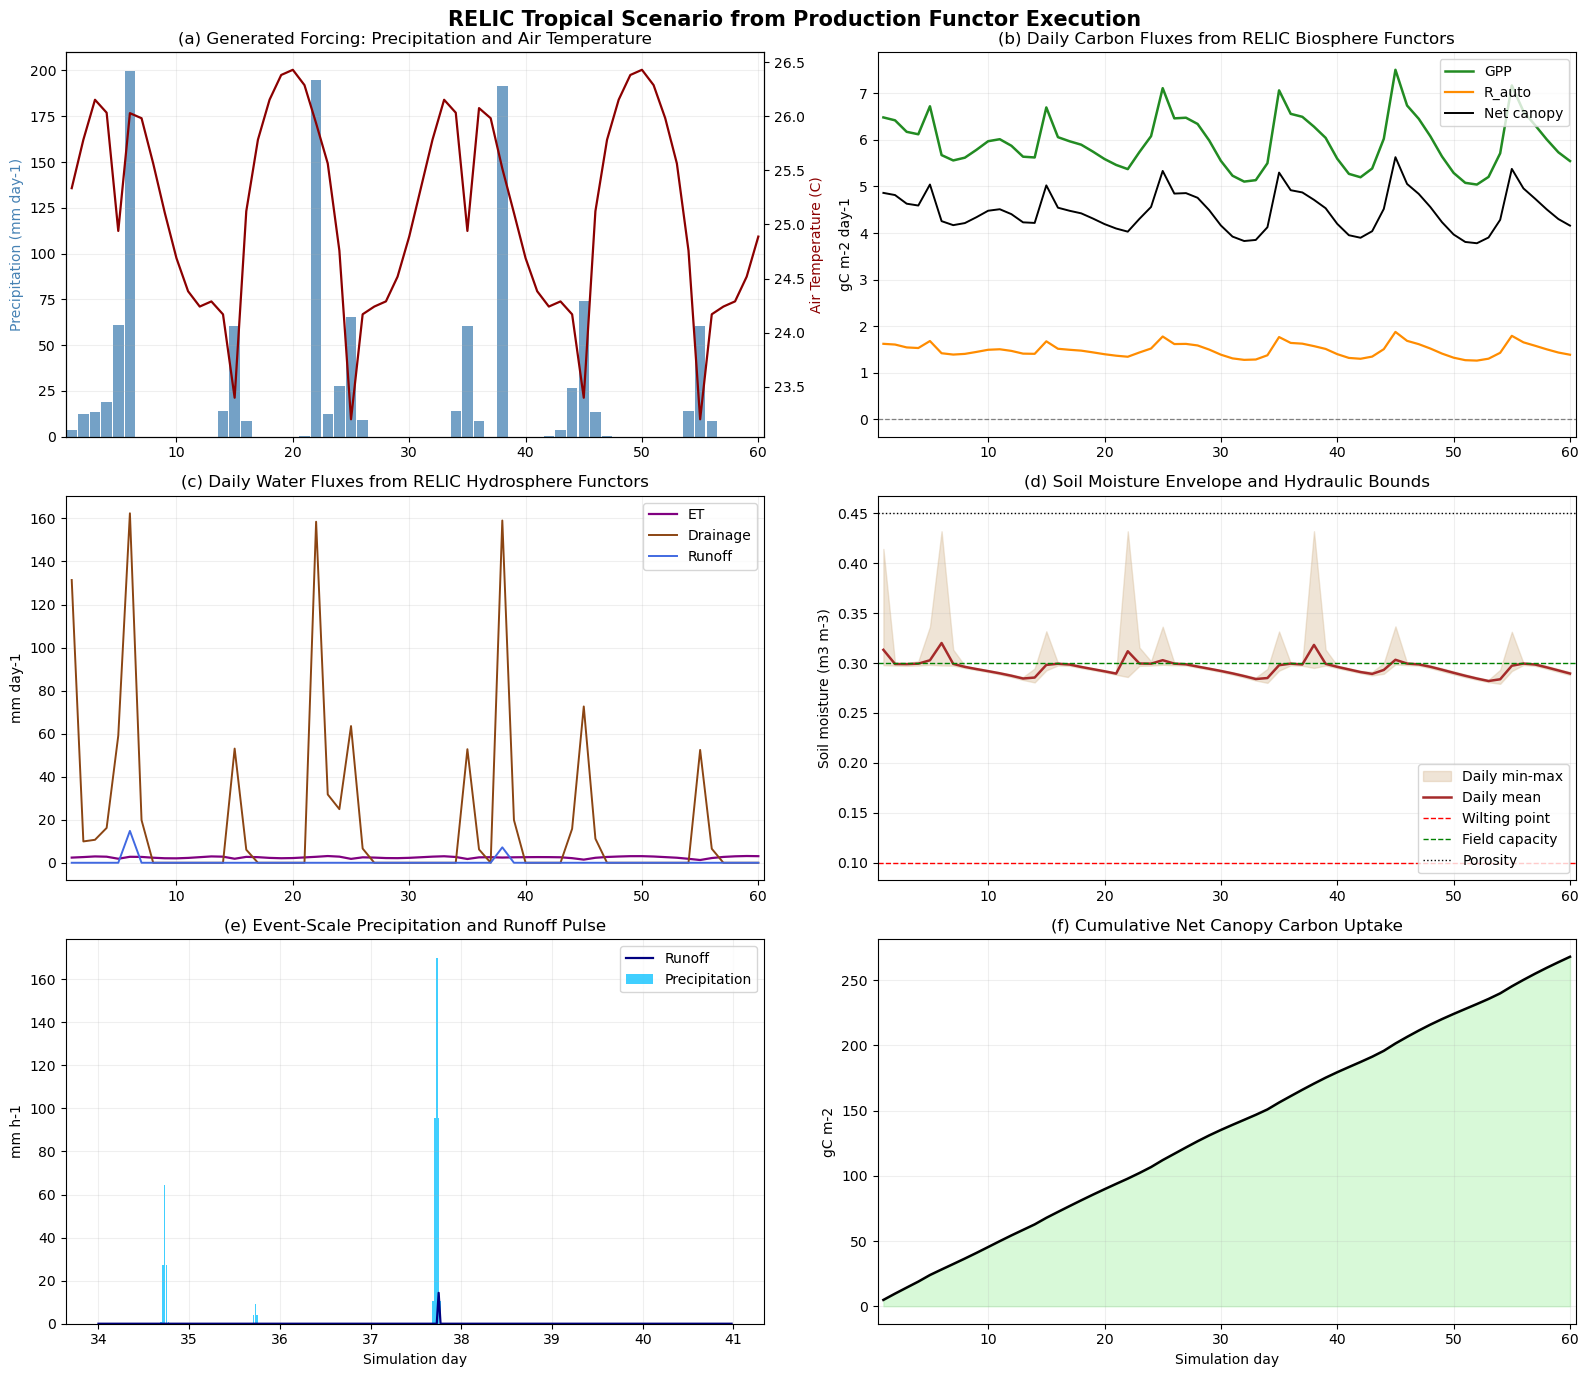

=== Visualization Summary ===
Peak daily GPP:        7.51 gC m-2 day-1
Peak daily ET:         3.13 mm day-1
Peak daily runoff:     14.81 mm day-1
Final cumulative sink: 267.96 gC m-2


In [5]:
# === Production Functor Scenario Visualization ===
import matplotlib.pyplot as plt
from IPython.display import display

plt.close('all')

wilting_point = 0.10
field_capacity = 0.30
porosity = 0.45

event_mask = (step_history['day_index'] >= 34.0) & (step_history['day_index'] <= 40.0)
event_time = (step_history['step_index'][event_mask] * dt / 86400.0).tolist()
event_precip_mm_h = (step_history['precip_flux'][event_mask] * 3600.0).tolist()
event_runoff_mm_h = (step_history['runoff_flux'][event_mask] * 3600.0).tolist()

fig, axes = plt.subplots(3, 2, figsize=(16, 14))

# Panel (a): daily precipitation and temperature
axes[0, 0].bar(daily['day_number'].tolist(), daily['precip_mm_day'].tolist(), color='steelblue', alpha=0.75, width=0.9)
ax_a2 = axes[0, 0].twinx()
ax_a2.plot(daily['day_number'].tolist(), daily['mean_air_temp_c'].tolist(), color='darkred', linewidth=1.6)
axes[0, 0].set_title('(a) Generated Forcing: Precipitation and Air Temperature')
axes[0, 0].set_ylabel('Precipitation (mm day-1)', color='steelblue')
ax_a2.set_ylabel('Air Temperature (C)', color='darkred')
axes[0, 0].set_xlim(0.5, duration_days + 0.5)

# Panel (b): daily carbon fluxes
axes[0, 1].plot(daily['day_number'].tolist(), daily['gpp_gC_day'].tolist(), color='forestgreen', linewidth=1.8, label='GPP')
axes[0, 1].plot(daily['day_number'].tolist(), daily['r_auto_gC_day'].tolist(), color='darkorange', linewidth=1.6, label='R_auto')
axes[0, 1].plot(daily['day_number'].tolist(), daily['net_canopy_gC_day'].tolist(), color='black', linewidth=1.4, label='Net canopy')
axes[0, 1].axhline(0.0, color='gray', linestyle='--', linewidth=0.9)
axes[0, 1].set_title('(b) Daily Carbon Fluxes from RELIC Biosphere Functors')
axes[0, 1].set_ylabel('gC m-2 day-1')
axes[0, 1].legend(loc='upper right')
axes[0, 1].set_xlim(0.5, duration_days + 0.5)

# Panel (c): daily hydrology fluxes
axes[1, 0].plot(daily['day_number'].tolist(), daily['et_mm_day'].tolist(), color='purple', linewidth=1.6, label='ET')
axes[1, 0].plot(daily['day_number'].tolist(), daily['drainage_mm_day'].tolist(), color='saddlebrown', linewidth=1.4, label='Drainage')
axes[1, 0].plot(daily['day_number'].tolist(), daily['runoff_mm_day'].tolist(), color='royalblue', linewidth=1.4, label='Runoff')
axes[1, 0].set_title('(c) Daily Water Fluxes from RELIC Hydrosphere Functors')
axes[1, 0].set_ylabel('mm day-1')
axes[1, 0].legend(loc='upper right')
axes[1, 0].set_xlim(0.5, duration_days + 0.5)

# Panel (d): soil moisture envelope
axes[1, 1].fill_between(
    daily['day_number'].tolist(),
    daily['min_soil_moisture'].tolist(),
    daily['max_soil_moisture'].tolist(),
    color='tan',
    alpha=0.35,
    label='Daily min-max'
)
axes[1, 1].plot(daily['day_number'].tolist(), daily['mean_soil_moisture'].tolist(), color='brown', linewidth=1.8, label='Daily mean')
axes[1, 1].axhline(wilting_point, color='red', linestyle='--', linewidth=1.0, label='Wilting point')
axes[1, 1].axhline(field_capacity, color='green', linestyle='--', linewidth=1.0, label='Field capacity')
axes[1, 1].axhline(porosity, color='black', linestyle=':', linewidth=1.0, label='Porosity')
axes[1, 1].set_title('(d) Soil Moisture Envelope and Hydraulic Bounds')
axes[1, 1].set_ylabel('Soil moisture (m3 m-3)')
axes[1, 1].legend(loc='lower right')
axes[1, 1].set_xlim(0.5, duration_days + 0.5)

# Panel (e): event-scale runoff pulse
axes[2, 0].bar(event_time, event_precip_mm_h, color='deepskyblue', alpha=0.75, width=0.018, label='Precipitation')
axes[2, 0].plot(event_time, event_runoff_mm_h, color='navy', linewidth=1.6, label='Runoff')
axes[2, 0].set_title('(e) Event-Scale Precipitation and Runoff Pulse')
axes[2, 0].set_xlabel('Simulation day')
axes[2, 0].set_ylabel('mm h-1')
axes[2, 0].legend(loc='upper right')

# Panel (f): cumulative net canopy balance
axes[2, 1].plot(daily['day_number'].tolist(), daily['cumulative_net_canopy_gC'].tolist(), color='black', linewidth=1.8)
axes[2, 1].fill_between(
    daily['day_number'].tolist(),
    [0.0] * duration_days,
    daily['cumulative_net_canopy_gC'].tolist(),
    color='lightgreen',
    alpha=0.35,
)
axes[2, 1].set_title('(f) Cumulative Net Canopy Carbon Uptake')
axes[2, 1].set_xlabel('Simulation day')
axes[2, 1].set_ylabel('gC m-2')
axes[2, 1].set_xlim(0.5, duration_days + 0.5)

for ax in axes.flat:
    ax.grid(True, alpha=0.2)

plt.suptitle('RELIC Tropical Scenario from Production Functor Execution', fontsize=15, fontweight='bold')
plt.tight_layout()
display(plt.gcf())
plt.close(plt.gcf())

print('=== Visualization Summary ===')
print(f"Peak daily GPP:        {float(daily['gpp_gC_day'].max()):.2f} gC m-2 day-1")
print(f"Peak daily ET:         {float(daily['et_mm_day'].max()):.2f} mm day-1")
print(f"Peak daily runoff:     {float(daily['runoff_mm_day'].max()):.2f} mm day-1")
print(f"Final cumulative sink: {float(daily['cumulative_net_canopy_gC'][-1]):.2f} gC m-2")

In [6]:
# ---------------------------------------------------------------
# References:
#   Functor metadata and runtime contracts from RELIC production modules
# Mathematical expression:
#   This cell documents variable handoff rather than solving a new process.
# Parameter meanings:
#   input_variables, output_variables, dependencies: RELIC functor metadata fields
# ---------------------------------------------------------------

print('=== RELIC Runtime Interface Summary ===')
for label, functor in [
    ('FarquharPhotosynthesis', photo),
    ('AutotrophicRespiration', resp),
    ('PenmanMonteithET', et_functor),
    ('BucketSoilMoisture', bucket),
]:
    metadata = functor.metadata
    print(f'--- {label} ---')
    print(f'  name:         {metadata.name}')
    print(f'  category:     {metadata.category}')
    print(f'  inputs:       {metadata.input_variables[:8]}')
    print(f'  outputs:      {metadata.output_variables[:8]}')
    if hasattr(functor, 'get_dependencies'):
        print(f'  dependencies: {functor.get_dependencies()}')
    print()

print('=== Direct Kernel Handoff Used In This Notebook ===')
print('1. Generated forcing -> FarquharPhotosynthesis')
print("   variables: ['air_temperature', 'atmospheric_co2_ppm', 'ppfd', 'leaf_area_index', 'water_stress_factor']")
print('2. FarquharPhotosynthesis -> AutotrophicRespiration')
print("   variables: ['gross_primary_productivity', 'maintenance_respiration_total', 'growth_respiration_total']")
print('3. Generated forcing -> PenmanMonteithET')
print("   variables: ['net_radiation', 'air_temperature', 'wind_speed', 'atmospheric_pressure', 'relative_humidity', 'surface_resistance']")
print('4. PenmanMonteithET -> BucketSoilMoisture')
print("   variables: ['evapotranspiration_flux', 'precipitation_flux', 'soil_moisture']")
print('5. BucketSoilMoisture diagnostics -> FarquharPhotosynthesis')
print("   variables: ['diagnostics.soil_moisture_bucket.water_stress_factor'] -> ['water_stress_factor']")
print()
print('[OK] Kernel outputs and declared local handoffs are shown; no simulator governance claim is made')

=== RELIC Runtime Interface Summary ===
--- FarquharPhotosynthesis ---
  name:         nb17_farquhar_photosynthesis
  category:     ProcessCategory.BIOLOGICAL_PROCESS
  inputs:       ['air_temperature', 'atmospheric_co2_ppm', 'ppfd', 'vapor_pressure_deficit', 'vcmax_scaling', 'vpmax_scaling', 'jmax_scaling', 'water_stress_factor']
  outputs:      ['gross_photosynthesis', 'net_photosynthesis', 'gross_primary_productivity', 'electron_transport_rate', 'diagnostics.photosynthesis.dark_respiration', 'diagnostics.photosynthesis.transport_limited', 'diagnostics.photosynthesis.jmax_actual', 'diagnostics.photosynthesis.limitation_factor']
  dependencies: ['environmental_forcing', 'atmospheric_radiation']

--- AutotrophicRespiration ---
  name:         nb17_autotrophic_respiration
  category:     ProcessCategory.BIOLOGICAL_PROCESS
  inputs:       ['gross_primary_productivity', 'maintenance_respiration_total', 'growth_respiration_total']
  outputs:      ['total_autotrophic_respiration', 'net_prim